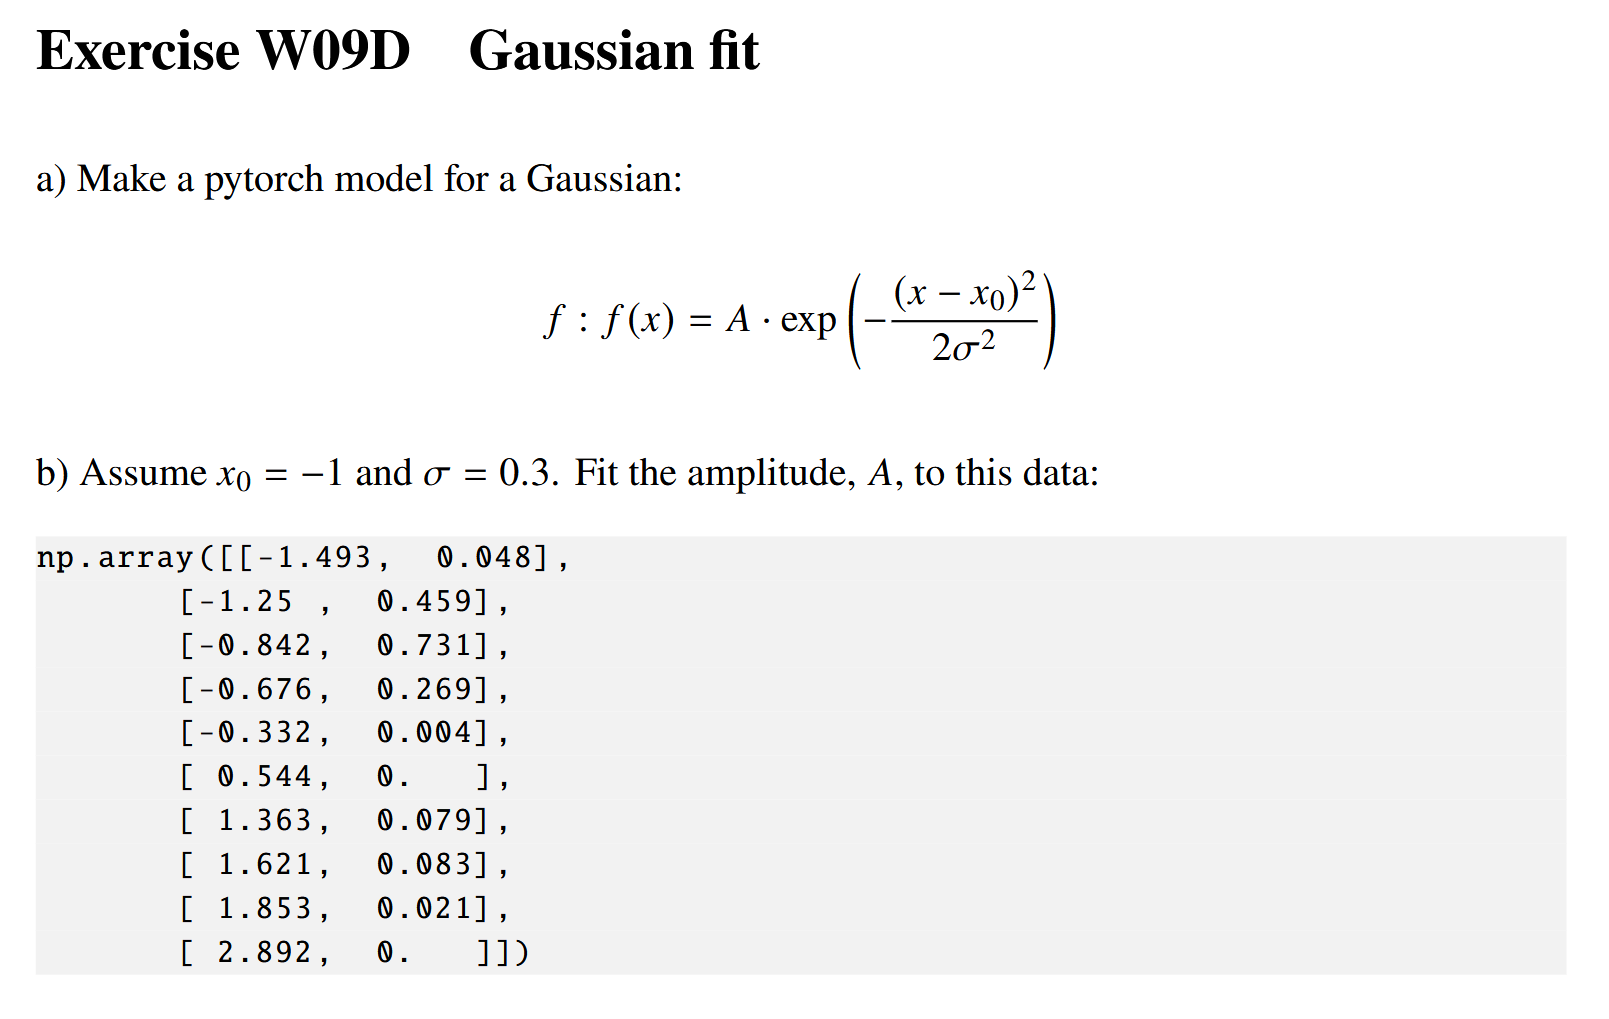

Fitted Amplitude (A): 0.6839


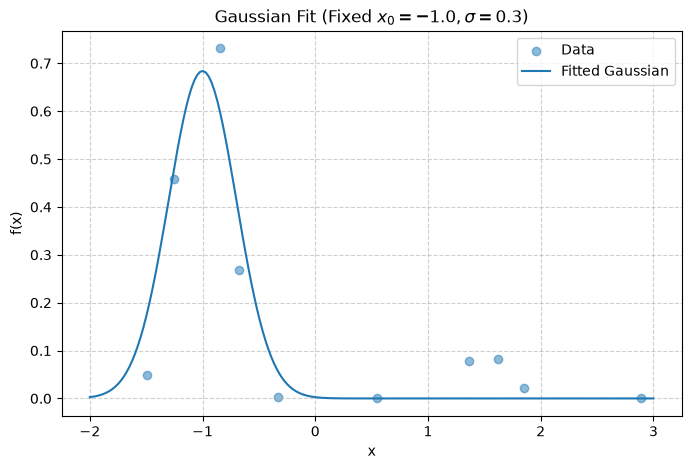

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

data = np.array([[-1.493, 0.048], 
                 [-1.25 , 0.459], 
                 [-0.842, 0.731], 
                 [-0.676, 0.269], 
                 [-0.332, 0.004], 
                 [ 0.544, 0.000], 
                 [ 1.363, 0.079], 
                 [ 1.621, 0.083], 
                 [ 1.853, 0.021], 
                 [ 2.892, 0.000]])

x_data = torch.tensor(data[:, 0], dtype=torch.float32)
y_data = torch.tensor(data[:, 1], dtype=torch.float32)

class GaussianModel(nn.Module):
    def __init__(self, A=1.0, x0=0.0, sigma=1.0):
        super().__init__()
        self.A = nn.Parameter(torch.tensor(A))
        self.x0 = nn.Parameter(torch.tensor(x0))
        self.s = nn.Parameter(torch.tensor(sigma))

    def forward(self, x):
        return self.A * torch.exp(-((x - self.x0)**2) / (2 * self.s**2))

model = GaussianModel(x0=-1.0, sigma=0.3)
optimizer = optim.Adam([model.A], lr=0.01)
criterion = nn.MSELoss()

epochs = 500
for epoch in range(epochs):
    optimizer.zero_grad()
    predictions = model(x_data)
    loss = criterion(predictions, y_data)
    loss.backward()
    optimizer.step()

print(f"Fitted Amplitude (A): {model.A.item():.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(x_data.numpy(), y_data.numpy(), alpha=0.5, label='Data')

x_smooth = torch.linspace(-2, 3, 200)
with torch.no_grad():
    y_smooth = model(x_smooth)

plt.plot(x_smooth.numpy(), y_smooth.numpy(), label='Fitted Gaussian')
plt.title(r"Gaussian Fit (Fixed $x_0=-1.0, σ=0.3$)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Fitted Amplitude (A): 0.0827


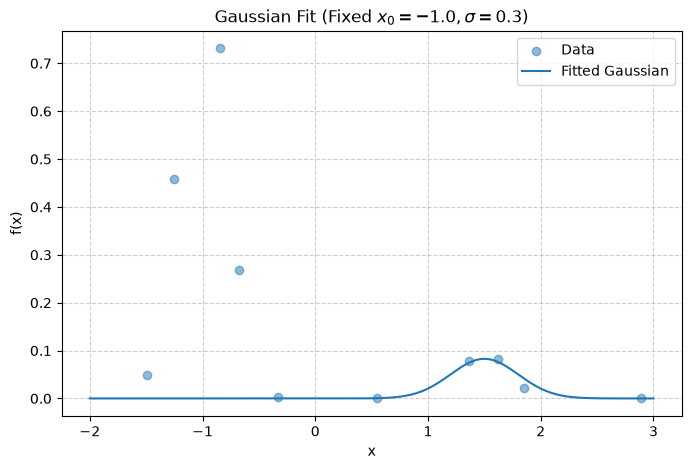

In [ ]:
model = GaussianModel(x0=1.5, sigma=0.3)
optimizer = optim.Adam([model.A], lr=0.01)
criterion = nn.MSELoss()

epochs = 500
for epoch in range(epochs):
    optimizer.zero_grad()
    predictions = model(x_data)
    loss = criterion(predictions, y_data)
    loss.backward()
    optimizer.step()

print(f"Fitted Amplitude (A): {model.A.item():.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(x_data.numpy(), y_data.numpy(), alpha=0.5, label='Data')

x_smooth = torch.linspace(-2, 3, 200)
with torch.no_grad():
    y_smooth = model(x_smooth)

plt.plot(x_smooth.numpy(), y_smooth.numpy(), label='Fitted Gaussian')
plt.title(r"Gaussian Fit (Fixed $x_0=1.5, σ=0.3$)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Fitted Amplitude (A): 0.9995


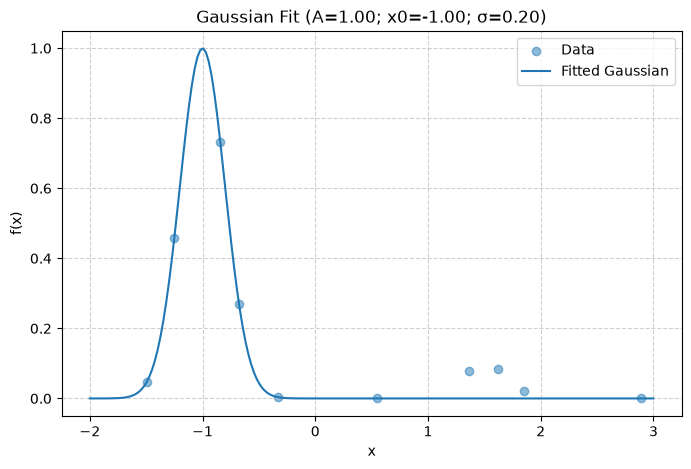

In [14]:
model = GaussianModel()
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

epochs = 500
for epoch in range(epochs):
    optimizer.zero_grad()
    predictions = model(x_data)
    loss = criterion(predictions, y_data)
    loss.backward()
    optimizer.step()

print(f"Fitted Amplitude (A): {model.A.item():.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(x_data.numpy(), y_data.numpy(), alpha=0.5, label='Data')

x_smooth = torch.linspace(-2, 3, 200)
with torch.no_grad():
    y_smooth = model(x_smooth)

plt.plot(x_smooth.numpy(), y_smooth.numpy(), label='Fitted Gaussian')
plt.title(f"Gaussian Fit (A={model.A.item():.2f}; x0={model.x0.item():.2f}; σ={model.s.item():.2f})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()